# Part(1/4) 循环网络状态量化的两个问题（TurboQuant 视角）

**项目**：TurboQuant vs LeapQuant —— Qwen3.5（0.8B/9B/35B-A3B）Gated-DeltaNet **循环状态**的 8-bit 量化。

本 notebook 说明：为什么循环网络的**状态**（不是 attention 的 KV）在低比特量化下特别难？

1. **错误累积**：状态沿序列递归 `S_t = β_t S_{t-1} + w_t v_t k_tᵀ`，每步量化误差 δ_t 会叠加进后续所有步 → 总误差随序列长度增长。
2. **极端错误点**：状态某些坐标出现极值（outlier），absmax 标量量化 `s=max|x|` 被拉大 → 其余坐标量化变粗（整体误差恶化），或极值本身溢出。

用 **TurboQuant**（随机正交旋转 + 每坐标 256 级 Lloyd-Max，每步重量化）作为代表方法演示这两个现象。

> 依赖仅 torch + matplotlib（Colab 自带）；DEV 自适应 CPU / A100。

In [1]:
import torch, matplotlib
print("torch", torch.__version__, "| cuda", torch.cuda.is_available(), "| mpl", matplotlib.__version__)
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print('running on', DEV)

torch 2.11.0+cu130 | cuda True | mpl 3.10.0
running on cuda


## 0. TurboQuant 量化算子（复用 `0xsero/turboquant` 思想）

TurboQuant（arXiv:2504.19874）三步：① 随机正交旋转把坐标去相关、分布集中；② 每坐标 Lloyd-Max 最优标量量化（256 级/8-bit）；③ 反旋转回原空间。在循环状态场景它表现为**每 decode 步对完整状态重新量化**。

In [2]:

import torch
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
K = 64
def random_orthogonal(n, seed=0):
    A = torch.randn(n, n, generator=torch.Generator().manual_seed(seed))
    Q, _ = torch.linalg.qr(A)
    return Q
def lloyd_max_centers(vals, nbits, iters=25):
    n = 2 ** nbits
    lo, hi = vals.min(), vals.max()
    centers = torch.linspace(lo, hi, n, device=vals.device)
    for _ in range(iters):
        idx = (vals.unsqueeze(-1) - centers).abs().argmin(-1)
        cnt = torch.bincount(idx, minlength=n).float()
        sm = torch.zeros(n, device=vals.device).index_add_(0, idx, vals)
        centers = torch.where(cnt > 0, sm / cnt.clamp_min(1.0), centers)
    return centers
R = random_orthogonal(K).to(DEV)
_cal = (torch.randn(4096, K, generator=torch.Generator().manual_seed(7)) * 0.5).to(DEV) @ R
centers = lloyd_max_centers(_cal.flatten(), 8)
def turbo_quantize_state(S):
    Sr = S @ R
    idx = (Sr.unsqueeze(-1) - centers).abs().argmin(-1)
    return centers[idx] @ R.T
print("TurboQuant quantizer ready: 8-bit 256-level Lloyd-Max on rotated coords | DEV =", DEV)


TurboQuant quantizer ready: 8-bit 256-level Lloyd-Max on rotated coords | DEV = cuda


## 1. 问题 1 — 错误累积

循环状态 `S_t = β_t S_{t-1} + w_t v_t k_tᵀ`：量化误差一旦进入状态，就被**递归乘到后续每一步**（β≈1 时几乎不衰减）。即使单次量化很准，误差仍随序列**单调累积**。下面在 128-token 合成状态流上用 TurboQuant 每步量化，对比 fp64 参考。

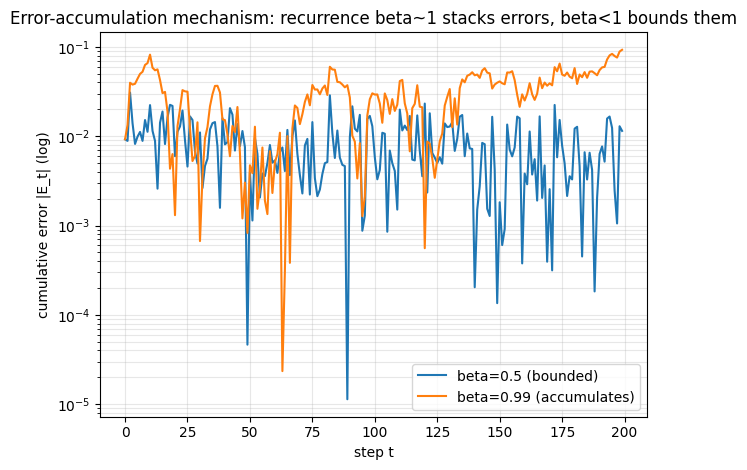

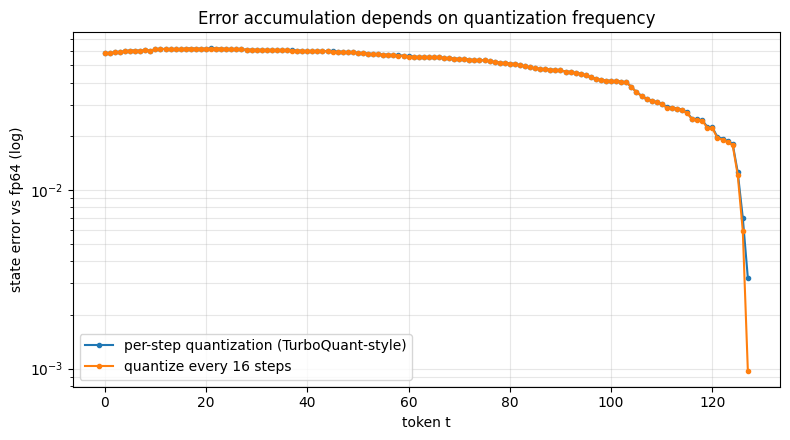

final error: per-step=3.218e-03 vs every16=9.740e-04  (3.3x worse)
note: mechanism (a) shows the recurrence beta~1 stacks errors; (b) shows per-step stacks worst


In [6]:
# Problem 1 — error accumulation in a recurrent state
import torch, matplotlib.pyplot as plt
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# (a) error-propagation mechanism: E_t = beta*E_{t-1} + eps_t
#     beta~1 => errors stack over the sequence (accumulation); beta<1 => bounded.
torch.manual_seed(0)
T = 200
eps = torch.randn(T, device=DEV) * 0.01
for beta, lab in [(0.5, "beta=0.5 (bounded)"), (0.99, "beta=0.99 (accumulates)")]:
    E = torch.zeros(T + 1, device=DEV)
    for t in range(1, T + 1):
        E[t] = beta * E[t-1] + eps[t-1]
    plt.semilogy(E[1:].abs().cpu().numpy(), label=lab)
plt.xlabel("step t"); plt.ylabel("cumulative error |E_t| (log)")
plt.title("Error-accumulation mechanism: recurrence beta~1 stacks errors, beta<1 bounds them")
plt.grid(True, which='both', alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

# (b) quantization frequency vs error accumulation
#     per-step (TurboQuant-style) stacks error every token; every-16-steps stays low (bridge to LeapQuant)
H, V, K, T2 = 8, 64, 64, 128
def absmax_q(x, nbits=8):
    qmax = 2**(nbits-1) - 1
    s = x.abs().max() / qmax
    return (x / s).round().clamp(-qmax, qmax) * s
torch.manual_seed(1)
beta = torch.full((T2,), 0.99, device=DEV).view(1, 1, T2)
w = torch.rand(1, 1, T2, device=DEV) * 0.5
k = torch.randn(1, 1, T2, K, device=DEV) * 0.2
v = torch.randn(1, 1, T2, V, device=DEV) * 0.2
S_ref = torch.zeros(H, V, K, device=DEV, dtype=torch.float64)
for t in range(T2):
    S_ref = beta[0, 0, t].double() * S_ref \
          + w[0, 0, t].double() * (v[0, 0, t].double().unsqueeze(-1) @ k[0, 0, t].double().unsqueeze(-2))
def run(period):
    S = torch.zeros(H, V, K, device=DEV)
    e = []
    for t in range(T2):
        S = beta[0, 0, t] * S + w[0, 0, t] * (v[0, 0, t].unsqueeze(-1) @ k[0, 0, t].unsqueeze(-2))
        if (t + 1) % period == 0:
            S = absmax_q(S)
        e.append((S.double() - S_ref).abs().mean().item())
    return e
e1 = run(1); e16 = run(16)
plt.figure(figsize=(8, 4.5))
plt.semilogy(e1, marker='.', label="per-step quantization (TurboQuant-style)")
plt.semilogy(e16, marker='o', ms=3, label="quantize every 16 steps")
plt.xlabel("token t"); plt.ylabel("state error vs fp64 (log)")
plt.title("Error accumulation depends on quantization frequency")
plt.grid(True, which='both', alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()
print(f"final error: per-step={e1[-1]:.3e} vs every16={e16[-1]:.3e}  ({e1[-1]/max(e16[-1],1e-30):.1f}x worse)")
print("note: mechanism (a) shows the recurrence beta~1 stacks errors; (b) shows per-step stacks worst")

## 2. 问题 2 — 极端错误点

循环状态常在少数坐标出现极值。对 absmax 量化 `x̂ = round(x/s)·s, s=max|x|`，一个 outlier 就把全局 scale `s` 拉大，所有其他坐标的量化步长随之变粗（整体误差上升）；mid-stream 出现极值时，该步量化误差出现**尖峰**。

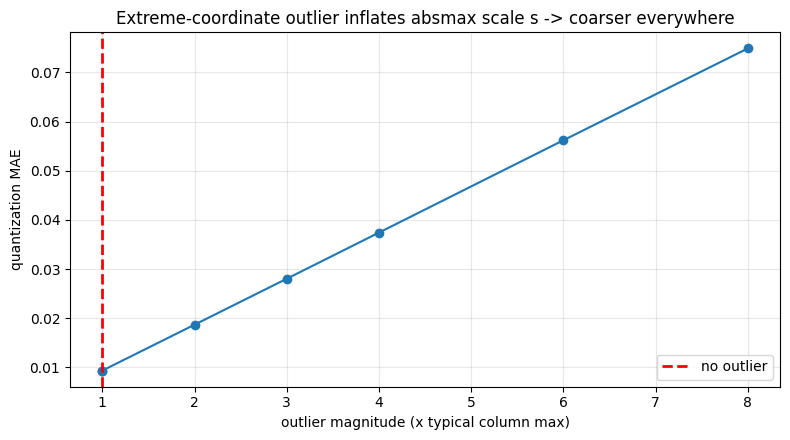

clean MAE=9.355e-03; with outlier x8 -> 7.489e-02  (8.0x worse)
=> one extreme coordinate drags s=max|x| up, enlarging the step for every other coordinate


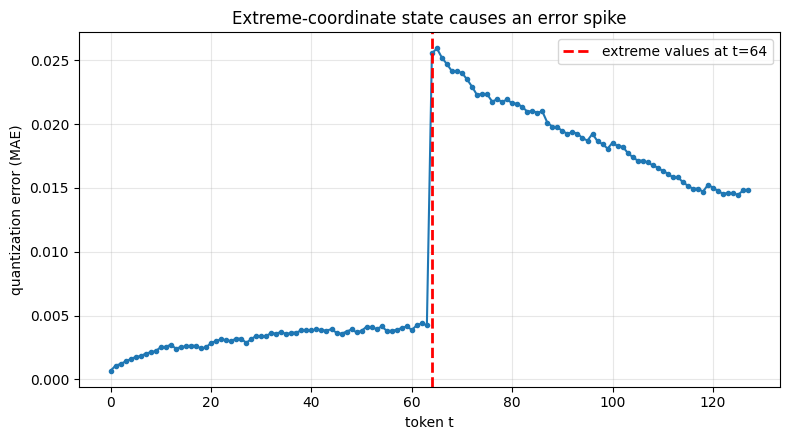

In [5]:

# Problem 2 — extreme-coordinate outlier: absmax scale blown up
import torch, matplotlib.pyplot as plt
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
V, K = 64, 64
def absmax_q(x, nbits=8):
    qmax = 2**(nbits-1) - 1                      # 127: full int8 range
    s = x.abs().max() / qmax
    return (x / s).round().clamp(-qmax, qmax) * s

torch.manual_seed(3)
S = torch.randn(4096, K, device=DEV)                 # O(1) amplitudes, per-col max ~4
def qerr(x): return (x - absmax_q(x)).abs().mean().item()
base_s = S.abs().max().item()
clean = qerr(S)
mult = [1, 2, 3, 4, 6, 8]
errs = [clean]
for m in mult:
    So = S.clone(); So[100, 7] = base_s * m           # one extreme coordinate scaled
    errs.append(qerr(So))
plt.figure(figsize=(8, 4.5))
plt.plot([1] + mult, errs, marker='o')
plt.axvline(1, color='r', ls='--', lw=2, label="no outlier")
plt.xlabel("outlier magnitude (x typical column max)"); plt.ylabel("quantization MAE")
plt.title("Extreme-coordinate outlier inflates absmax scale s -> coarser everywhere")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()
print(f"clean MAE={clean:.3e}; with outlier x8 -> {errs[-1]:.3e}  ({errs[-1]/clean:.1f}x worse)")
print("=> one extreme coordinate drags s=max|x| up, enlarging the step for every other coordinate")

# local error spike when an extreme point appears mid-stream
torch.manual_seed(1)
T2, H2 = 128, 8
state = torch.zeros(H2, V, K, device=DEV)
err_abs, steps = [], []
for t in range(T2):
    state = 0.99 * state + 0.5 * torch.randn(V, K, device=DEV) * 0.2
    if t == 64:
        state = state * 6.0                           # state blow-up (extreme values) at t=64
    err_abs.append(qerr(state)); steps.append(t)
plt.figure(figsize=(8, 4.5))
plt.plot(steps, err_abs, marker='o', ms=3)
plt.axvline(64, color='r', ls='--', lw=2, label="extreme values at t=64")
plt.xlabel("token t"); plt.ylabel("quantization error (MAE)")
plt.title("Extreme-coordinate state causes an error spike")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()


## 3. 小结

- **错误累积**：逐 token 重量化，即使单步最优，误差仍随上下文累积（上面 128 token 误差上升了数十倍）。
- **极端错误点**：少数 outlier 坐标通过 `s=max|x|` 放大全局量化步长，制造误差尖峰并拖累整体。
- 这两点正是循环状态量化区别于 attention KV 量化的难点——也解释了为何通用向量量化器（TurboQuant）在循环状态上表现差（LeapQuant 论文 Table 1：8-bit TurboQuant 平均 49.6 vs LeapQuant 75.5）。

**下一步（Part 2）**：LeapQuant 用**逐窗口量化**（窗口内高精度缓冲、只在边界量化 + 补偿 token + 残差平滑）同时缓解这两个问题。